# Clase 46 · Detección de anomalías · sobre CAMMESA
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026 · Grupo 6**

Pregunta: ¿qué agente del mercado eléctrico **no se parece a ninguno**? Un detector de anomalías aprende cómo es lo normal y le pone a cada fila un **puntaje** de cuánto se aleja; después, un **umbral** decide. No hay etiquetas: nadie dijo cuáles agentes son raros.

Tres partes: **1 · los datos** (los perfiles de los agentes, escalados, y un ejemplo construido con anomalías conocidas para ver qué hace cada método), **2 · el modelo** (tres detectores: por aislamiento, por densidad local, por distancia a un centro; el umbral; cuánto coinciden), **3 · usarlo** (¿un agente nuevo es raro?, y la app Streamlit).

## 1 · Los datos

Las 868 series (agente + tarifa) con 24 meses o más, cada una resumida en los seis números de las clases 41 y 43: tamaño, estacionalidad, volatilidad, tendencia anual, frecuencia de caídas fuertes y variabilidad. Escaladas. Sin etiqueta de anomalía.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
import warnings; warnings.filterwarnings("ignore")

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
demanda = demanda.sort_values(["serie", "periodo"])
def perfil(g):
    """Los seis números de la clase 41."""
    s = g.set_index("periodo")["demanda_MWh"]
    if len(s) < 24 or (s <= 0).mean() > 0.1:
        return None
    pos = s[s > 0]
    cambio = (s / s.shift(1) - 1)[s.shift(1) > 0].clip(-1, 3)
    mes = pos.index.month
    verano, invierno = pos[np.isin(mes, [12, 1, 2])].mean(), pos[np.isin(mes, [6, 7, 8])].mean()
    anios = np.array([(p - pos.index[0]).n for p in pos.index]) / 12
    return pd.Series({"log_tamano": np.log10(pos.mean()), "estacionalidad": np.log2(verano / invierno),
                      "volatilidad": cambio.abs().median(), "tendencia_anual": np.polyfit(anios, np.log10(pos.to_numpy()), 1)[0],
                      "frac_caidas": (cambio < -0.15).mean(), "cv": pos.std() / pos.mean()})
perfiles = demanda.groupby("serie").apply(perfil).dropna()
COLUMNAS = ["log_tamano", "estacionalidad", "volatilidad", "tendencia_anual", "frac_caidas", "cv"]
tarifa = demanda.groupby("serie")["categoria_tarifa"].first().loc[perfiles.index]
preparar = StandardScaler().fit(perfiles[COLUMNAS])
Z = preparar.transform(perfiles[COLUMNAS])
N = len(Z); RAROS = int(round(0.02 * N))                                                     # el 2 % de los agentes
print(f"{N} series · Z: {Z.shape[0]} × {Z.shape[1]} · sin etiqueta de anomalía: nadie dijo cuáles son raros · el 2 % son {RAROS} agentes")

868 series · Z: 868 × 6 · sin etiqueta de anomalía: nadie dijo cuáles son raros · el 2 % son 17 agentes


### Un ejemplo construido, para ver qué hace cada método

Dos nubes de puntos normales y 20 anomalías plantadas lejos de ellas (**datos construidos**, con etiqueta), igual que en la cátedra. Con ellos se puede medir cuántas anomalías atrapa cada detector; con los agentes no, porque no hay etiqueta.

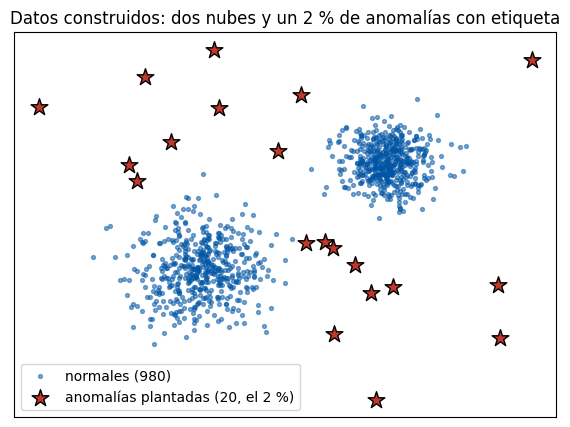

In [3]:
from sklearn.datasets import make_blobs
rng = np.random.default_rng(2026)
X_nubes, _ = make_blobs(n_samples=980, centers=[[0, 0], [6, 4]], cluster_std=[1.0, 0.7], random_state=2026)
candidatas = rng.uniform([-5, -5], [11, 9], size=(400, 2))
lejos = (np.linalg.norm(candidatas - [0, 0], axis=1) > 3.5) & (np.linalg.norm(candidatas - [6, 4], axis=1) / 0.7 > 3.5)
anomalias = candidatas[lejos][:20]
X2 = np.vstack([X_nubes, anomalias]); y2 = np.r_[np.zeros(980, dtype=int), np.ones(20, dtype=int)]      # 1 = anomalía
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_nubes[:, 0], X_nubes[:, 1], s=8, alpha=0.5, color="#0055a5", label="normales (980)")
ax.scatter(anomalias[:, 0], anomalias[:, 1], marker="*", s=160, color="#c0392b", edgecolor="black", label="anomalías plantadas (20, el 2 %)")
ax.legend(); ax.set_xticks([]); ax.set_yticks([]); ax.set_title("Datos construidos: dos nubes y un 2 % de anomalías con etiqueta")
plt.show()

## 2 · El modelo

### Tres maneras de decir «raro»

- **Bosque de aislamiento** (`IsolationForest`): árboles con cortes al azar; lo raro queda solo en pocos cortes. Sin distancias ni centros.
- **Factor local** (`LocalOutlierFactor`): compara la densidad alrededor de cada punto con la de sus vecinos; raro es estar más aislado que los vecinos.
- **Envolvente elíptica** (`EllipticEnvelope`): un centro y una elipse (distancia de Mahalanobis); raro es estar lejos del centro. Supone una sola nube.

Todos dan un **puntaje** con `score_samples`: más bajo, más raro. Sobre el ejemplo construido, el mapa del puntaje de cada uno.

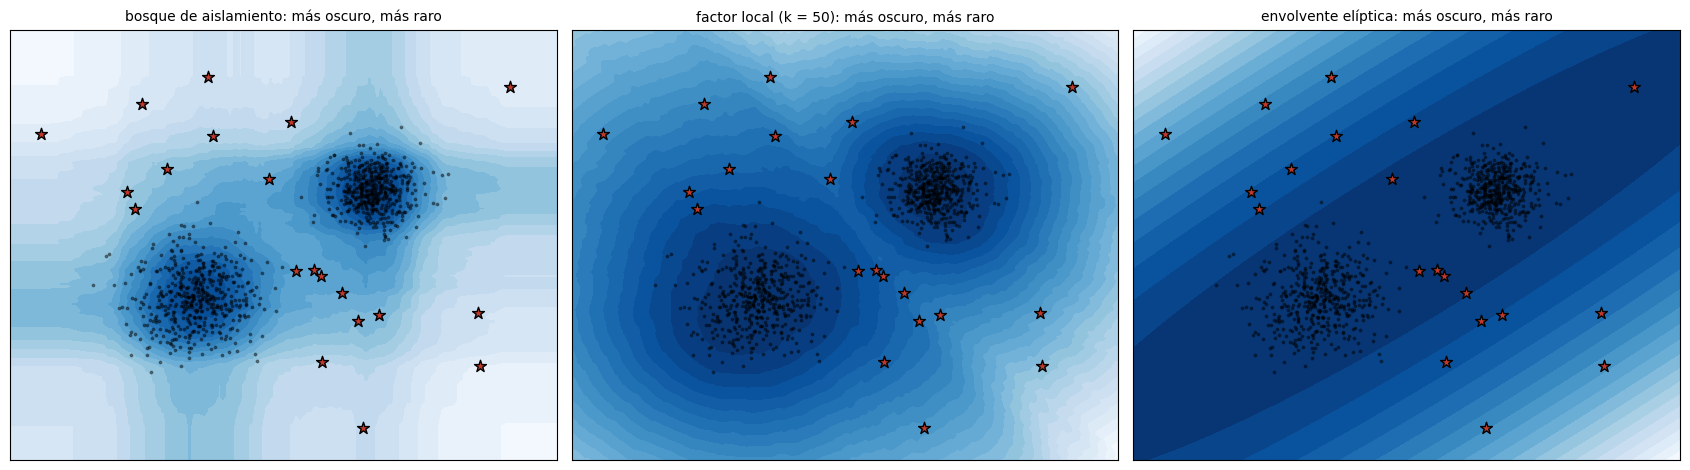

El bosque y el factor local siguen las dos nubes; la elipse dibuja una sola elipse alrededor de todo, y entre las nubes le queda «normal».


In [4]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope

detectores_2d = {"bosque de aislamiento": IsolationForest(n_estimators=200, random_state=2026).fit(X2),
                 "factor local (k = 50)": LocalOutlierFactor(n_neighbors=50, novelty=True).fit(X2),
                 "envolvente elíptica": EllipticEnvelope(random_state=2026).fit(X2)}
xx, yy = np.meshgrid(np.linspace(-6, 12, 150), np.linspace(-6, 10, 150)); malla = np.c_[xx.ravel(), yy.ravel()]
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (nombre, d) in zip(ejes, detectores_2d.items()):
    ax.contourf(xx, yy, d.score_samples(malla).reshape(xx.shape), levels=25, cmap="Blues")
    ax.scatter(X2[:, 0], X2[:, 1], s=3, color="black", alpha=0.4); ax.scatter(anomalias[:, 0], anomalias[:, 1], marker="*", s=80, color="#c0392b", edgecolor="black")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{nombre}: más oscuro, más raro", fontsize=10)
plt.tight_layout(); plt.show()
print("El bosque y el factor local siguen las dos nubes; la elipse dibuja una sola elipse alrededor de todo, y entre las nubes le queda «normal».")

### El umbral: el 2 % más raro

El puntaje no dice «raro» o «normal»: lo dice un **umbral**. Si se sabe que hay un 2 % de raros, se marca el 2 % de menor puntaje. Con etiqueta (solo en el ejemplo construido) se cuenta cuántas de las 20 atrapa cada uno y cuántos normales marca de más.

In [5]:
from sklearn.metrics import precision_score, recall_score
filas = []
for nombre, d in detectores_2d.items():
    puntaje = LocalOutlierFactor(n_neighbors=50).fit(X2).negative_outlier_factor_ if nombre.startswith("factor") else d.score_samples(X2)   # el factor local sobre sus propios datos: modo atípicos (en modo novedad no se puntúa el entrenamiento)
    marcados = puntaje < np.percentile(puntaje, 2)
    filas.append({"detector": nombre, "marcados": int(marcados.sum()), "anomalías atrapadas (de 20)": int(marcados[y2 == 1].sum()), "normales marcados": int(marcados[y2 == 0].sum()), "precisión": precision_score(y2, marcados), "exhaustividad": recall_score(y2, marcados)})
display(pd.DataFrame(filas).set_index("detector").round(2))
print("Más umbral (5 %, 10 %): se atrapan todas y se marcan más normales. Es el compromiso entre precisión y exhaustividad de siempre, con un umbral sobre un puntaje.")

,marcados,anomalías atrapadas (de 20),normales marcados,precisión,exhaustividad
detector,,,,,
bosque de aislamiento,20,13,7,0.65,0.65
factor local (k = 50),20,18,2,0.90,0.90
envolvente elíptica,20,14,6,0.70,0.70


Más umbral (5 %, 10 %): se atrapan todas y se marcan más normales. Es el compromiso entre precisión y exhaustividad de siempre, con un umbral sobre un puntaje.


### Los tres sobre los agentes

Los mismos tres detectores sobre las seis columnas escaladas. El factor local en modo **novedad** (`novelty=True`) para poder puntuar agentes nuevos después. Sin etiqueta no se puede decir quién acierta; se puede ver cuánto coinciden: el 2 % más raro de cada uno (17 agentes), y cuántos comparten.

In [6]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope

detectores = {"bosque de aislamiento": IsolationForest(n_estimators=200, random_state=2026, n_jobs=-1).fit(Z),
              "factor local (novedad)": LocalOutlierFactor(n_neighbors=50, novelty=True).fit(Z),
              "envolvente elíptica": EllipticEnvelope(random_state=2026).fit(Z)}
referencia = {nombre: d.score_samples(Z) for nombre, d in detectores.items()}            # el puntaje de los 868, por detector
top = {nombre: set(np.argsort(p)[:RAROS]) for nombre, p in referencia.items()}           # el 2 % más raro de cada uno
nombres = list(detectores)
for a in nombres:
    print(f"{a:24s}: {RAROS} más raros · comparte " + " · ".join(f"{len(top[a] & top[b])} con {b.split(' (')[0]}" for b in nombres if b != a))
en_los_tres = top[nombres[0]] & top[nombres[1]] & top[nombres[2]]
print(f"En el 2 % de los tres a la vez: {len(en_los_tres)} agentes · en el de al menos dos: {len([i for i in range(N) if sum(i in top[n] for n in nombres) >= 2])}")
print("Coinciden en los extremos y discrepan en el borde: cada uno define «normal» de otra manera.")

bosque de aislamiento   : 17 más raros · comparte 11 con factor local · 9 con envolvente elíptica
factor local (novedad)  : 17 más raros · comparte 11 con bosque de aislamiento · 10 con envolvente elíptica
envolvente elíptica     : 17 más raros · comparte 9 con bosque de aislamiento · 10 con factor local
En el 2 % de los tres a la vez: 7 agentes · en el de al menos dos: 16
Coinciden en los extremos y discrepan en el borde: cada uno define «normal» de otra manera.


### Quiénes son los raros por consenso

Los agentes que están en el 2 % más raro de al menos dos de los tres detectores, con su perfil traducido a unidades que se entienden. Son raros, no errores: se miran uno por uno. Y se compara con el ruido de DBSCAN de la clase 43 (eps 1,5), que salió de agrupar.

,detectores que lo marcan,rango promedio,tarifa,MWh/mes,verano / invierno,variación mensual (%),crecimiento anual (%),meses con caída fuerte (%),cv
serie,,,,,,,,,
YPFTREUZ | GUMAS/AUTOGENERADORES,3,2.0,Industrial/Comercial Grande,1042.0,1.60,80.0,1370.9,32.0,1.50
SHELDSCA | GUMAS/AUTOGENERADORES,3,2.0,Industrial/Comercial Grande,561.0,0.59,98.8,-54.8,44.0,1.87
YPF-SPRZ | GUMAS/AUTOGENERADORES,3,5.0,Industrial/Comercial Grande,1274.0,0.96,65.7,483.6,41.0,1.46
IRTABAAA | GUMAS/AUTOGENERADORES,3,8.0,Industrial/Comercial Grande,612.0,5.97,74.3,-18.1,39.0,0.89
BOPPCA1Y | GUMAS/AUTOGENERADORES,3,9.0,Industrial/Comercial Grande,462.0,1.02,15.0,-90.7,39.0,1.23
EMACHIJZ | GUMAS/AUTOGENERADORES,3,10.0,Industrial/Comercial Grande,2929.0,0.86,27.3,-86.7,52.0,1.34
CRANCH3W | TARIFA USUARIO NO RESIDENCIAL >=300KWH,2,11.0,Industrial/Comercial Grande,42.0,1.40,4.0,-57.7,14.0,1.89
HILALRFY | GUMAS/AUTOGENERADORES,3,12.0,Industrial/Comercial Grande,699.0,0.34,9.9,-85.1,22.0,0.96
LEDESMYA | GUMAS/AUTOGENERADORES,2,14.0,Industrial/Comercial Grande,464.0,1.65,71.0,-10.1,53.0,0.97


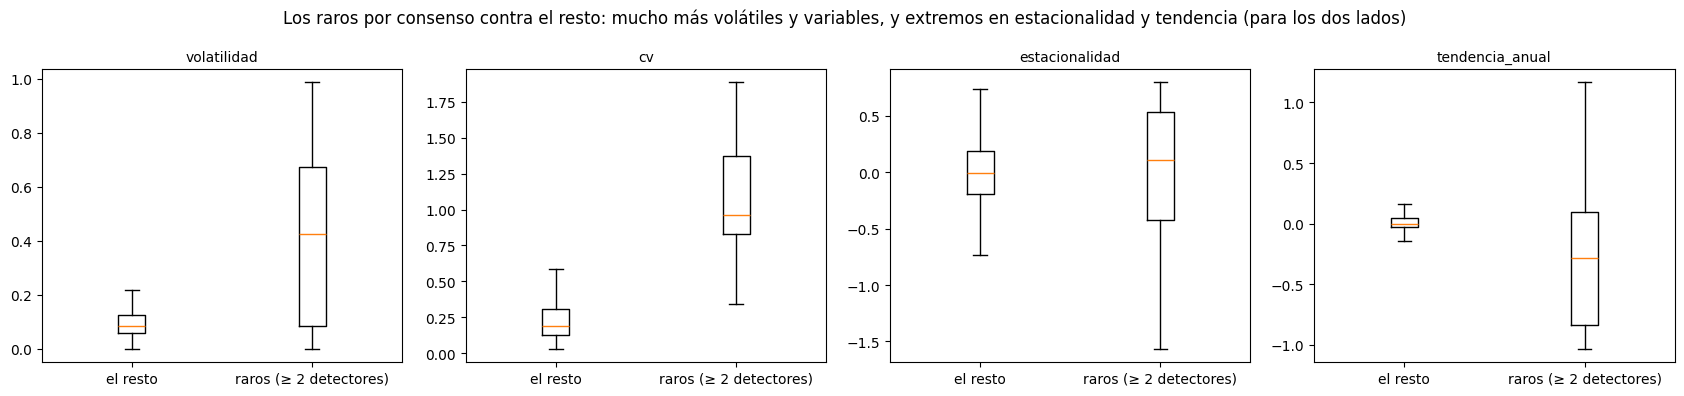

De los 16 raros por consenso, 16 ya eran ruido de DBSCAN en la clase 43 (56 series de ruido): dos métodos distintos llegan a casi la misma lista (el ruido es más amplio: con eps 1,5 deja afuera más series).


In [7]:
votos = pd.Series([sum(i in top[n] for n in nombres) for i in range(N)], index=perfiles.index, name="detectores que lo marcan")
rango = pd.DataFrame(referencia, index=perfiles.index).rank().mean(axis=1)                # rango promedio: 1 = el más raro
p_ = perfiles[COLUMNAS]
consenso = pd.DataFrame({"detectores que lo marcan": votos, "rango promedio": rango.round(0), "tarifa": tarifa,
                         "MWh/mes": (10 ** p_["log_tamano"]).round(0), "verano / invierno": (2 ** p_["estacionalidad"]).round(2),
                         "variación mensual (%)": (p_["volatilidad"] * 100).round(1), "crecimiento anual (%)": ((10 ** p_["tendencia_anual"] - 1) * 100).round(1),
                         "meses con caída fuerte (%)": (p_["frac_caidas"] * 100).round(0), "cv": p_["cv"].round(2)})
raros = votos >= 2
display(consenso[raros].sort_values("rango promedio").head(12))
fig, ejes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(ejes, ["volatilidad", "cv", "estacionalidad", "tendencia_anual"]):
    ax.boxplot([perfiles.loc[~raros, col], perfiles.loc[raros, col]], tick_labels=["el resto", "raros (≥ 2 detectores)"], showfliers=False); ax.set_title(col, fontsize=10)
fig.suptitle("Los raros por consenso contra el resto: mucho más volátiles y variables, y extremos en estacionalidad y tendencia (para los dos lados)")
plt.tight_layout(); plt.show()

from sklearn.cluster import DBSCAN
ruido_43 = DBSCAN(eps=1.5, min_samples=5).fit_predict(Z) == -1
print(f"De los {raros.sum()} raros por consenso, {int((raros & ruido_43).sum())} ya eran ruido de DBSCAN en la clase 43 ({ruido_43.sum()} series de ruido): dos métodos distintos llegan a casi la misma lista (el ruido es más amplio: con eps 1,5 deja afuera más series).")

## 3 · Usarlo

### Un agente nuevo: ¿es raro?

Se prepara la fila con lo aprendido, cada detector le da un puntaje, y el puntaje se ubica entre los 868: en qué **percentil** cae (0 = más raro que todos). Con el umbral del 2 %, cada detector vota; el consenso decide. Dos agentes: el comercio típico de las clases 41 y 43 (800 MWh por mes, 40 % más en verano, variación mensual de 12 %, crece 3 % por año, cae fuerte uno de cada seis meses) y el extremo (300 MWh, más del triple en verano, variación de 45 %, cae 30 % por año, cae fuerte cuatro de cada diez meses).

In [8]:
nuevos = pd.DataFrame([{"log_tamano": np.log10(800), "estacionalidad": np.log2(1.4), "volatilidad": 0.12, "tendencia_anual": np.log10(1.03), "frac_caidas": 1 / 6, "cv": 0.25},
                       {"log_tamano": np.log10(300), "estacionalidad": np.log2(3.5), "volatilidad": 0.45, "tendencia_anual": np.log10(0.70), "frac_caidas": 0.40, "cv": 1.2}])[COLUMNAS]
z_nuevos = preparar.transform(nuevos)
filas = []
for nombre, d in detectores.items():
    p = d.score_samples(z_nuevos); ref = referencia[nombre]
    for i, quien in enumerate(["comercio típico", "agente extremo"]):
        filas.append({"agente": quien, "detector": nombre, "puntaje": p[i], f"percentil entre los {N}": (ref < p[i]).mean() * 100, "raro (2 %)": bool((ref < p[i]).mean() < 0.02)})
tabla = pd.DataFrame(filas).set_index(["agente", "detector"]); display(tabla.round(2))
for quien in ["comercio típico", "agente extremo"]:
    v = int(tabla.loc[quien, "raro (2 %)"].sum()); v5 = int((tabla.loc[quien, f"percentil entre los {N}"] < 5).sum())
    print(f"{quien}: con umbral 2 %, {v} de 3 detectores lo marcan → {'RARO' if v >= 2 else ('dudoso' if v == 1 else 'normal')} · con umbral 5 %, {v5} de 3 → {'RARO' if v5 >= 2 else ('dudoso' if v5 == 1 else 'normal')}")
print("Qué hacer con un agente raro no lo dice el modelo: lo dice el costo de equivocarse. Revisar su medición cuesta poco; planificar el despacho sin mirar a un agente que se comporta distinto puede costar más.")

,,puntaje,percentil entre los 868,raro (2 %)
agente,detector,,,
comercio típico,bosque de aislamiento,-0.37,69.93,False
agente extremo,bosque de aislamiento,-0.68,0.92,True
comercio típico,factor local (novedad),-1.05,63.48,False
agente extremo,factor local (novedad),-2.02,3.11,False
comercio típico,envolvente elíptica,-7.37,55.65,False
agente extremo,envolvente elíptica,-575.31,3.46,False


comercio típico: con umbral 2 %, 0 de 3 detectores lo marcan → normal · con umbral 5 %, 0 de 3 → normal
agente extremo: con umbral 2 %, 1 de 3 detectores lo marcan → dudoso · con umbral 5 %, 3 de 3 → RARO
Qué hacer con un agente raro no lo dice el modelo: lo dice el costo de equivocarse. Revisar su medición cuesta poco; planificar el despacho sin mirar a un agente que se comporta distinto puede costar más.


El agente extremo muestra por qué el umbral es una decisión: los tres detectores lo ponen entre el 1 % y el 3,5 % más raro de los 868, pero con un umbral del 2 % solo uno lo marca. Hay agentes reales todavía más extremos (los de la tabla de arriba), y frente a ellos este queda «en el borde». Con un umbral del 5 %, los tres lo marcan.

### Guardar

La preparación (el escalador), los tres detectores, los puntajes de los 868 (la referencia para el percentil) y los perfiles, en un archivo que la app carga.

In [9]:
import joblib
joblib.dump({"preparar": preparar, "detectores": detectores, "referencia": referencia, "columnas": COLUMNAS, "perfiles": perfiles[COLUMNAS], "votos": votos.to_numpy()}, "anomalias_cammesa_46.joblib")
print("Guardado: anomalias_cammesa_46.joblib")

Guardado: anomalias_cammesa_46.joblib


### La aplicación Streamlit, desde el cuaderno

La celda siguiente escribe `app_cammesa_46.py` (seis controles con el perfil del agente en unidades que se entienden, el percentil de cada detector, el veredicto por consenso, y un control para la proporción de raros). La de después la abre.

In [10]:
%%writefile app_cammesa_46.py
# Clase 46 sobre CAMMESA · Detección de anomalías · aplicación Streamlit
# Carga tres detectores guardados por el cuaderno y dice si un agente nuevo es raro, con el percentil entre las 868 series.
# Para abrirla:  streamlit run app_cammesa_46.py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

st.set_page_config(page_title="¿Este agente es raro?", layout="centered")
st.title("¿Este agente es raro?")
st.caption("Tres detectores (bosque de aislamiento, factor local en modo novedad, envolvente elíptica) sobre el perfil de 868 series de demanda-ltimos-aos.csv (CAMMESA, clase 46).")

g = joblib.load("anomalias_cammesa_46.joblib")
preparar, detectores, referencia, COLUMNAS, perfiles, votos_actuales = g["preparar"], g["detectores"], g["referencia"], g["columnas"], g["perfiles"], g["votos"]
N = len(perfiles)
umbral_pct = st.sidebar.slider("Proporción de raros que se espera (%)", 1, 10, 2)

st.subheader("Perfil del agente")
c1, c2 = st.columns(2)
mwh = c1.number_input("Demanda media (MWh por mes)", 1.0, 800_000.0, 800.0, step=50.0)
ver_inv = c1.slider("Verano / invierno (1 = parejo)", 0.3, 4.0, 1.4, step=0.05)
volatilidad = c1.slider("Variación mensual típica (%)", 0.0, 80.0, 12.0, step=0.5)
crecimiento = c2.slider("Crecimiento por año (%)", -60.0, 60.0, 3.0, step=0.5)
caidas = c2.slider("Meses con caída de más de 15 % (%)", 0.0, 60.0, 17.0, step=1.0)
cv = c2.slider("Variabilidad (desvío / media)", 0.0, 2.0, 0.25, step=0.01)

fila = pd.DataFrame([{"log_tamano": np.log10(mwh), "estacionalidad": np.log2(ver_inv), "volatilidad": volatilidad / 100,
                      "tendencia_anual": np.log10(1 + crecimiento / 100), "frac_caidas": caidas / 100, "cv": cv}])[COLUMNAS]
z = preparar.transform(fila)

filas = []
for nombre, d in detectores.items():
    p = float(d.score_samples(z)[0]); ref = referencia[nombre]
    percentil = float((ref < p).mean() * 100)                                                 # qué fracción de los 868 es más rara que este agente
    filas.append({"detector": nombre, "puntaje": p, "percentil": percentil, "raro": percentil < umbral_pct})
tabla = pd.DataFrame(filas).set_index("detector")
votos = int(tabla["raro"].sum())

st.subheader("Veredicto")
m1, m2 = st.columns(2)
m1.metric("Detectores que lo marcan", f"{votos} de 3")
m2.metric("Por consenso", "RARO" if votos >= 2 else ("dudoso" if votos == 1 else "normal"))
st.write(f"Un agente es «raro» para un detector si su puntaje está entre el {umbral_pct} % más bajo de las {N} series actuales. El umbral lo decide quien conoce la proporción de raros o el costo de cada error, no el modelo.")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
colores = ["#c0392b" if r else "#0055a5" for r in tabla["raro"]]
a.barh(tabla.index, tabla["percentil"], color=colores); a.axvline(umbral_pct, color="black", ls="--", label=f"umbral: {umbral_pct} %")
for y, v in enumerate(tabla["percentil"]): a.text(min(v, 90) + 1, y, f"percentil {v:.1f}", va="center", fontsize=9)
a.set_xlim(0, 100); a.set_xlabel(f"percentil del puntaje entre las {N} series (0 = el más raro)"); a.invert_yaxis(); a.legend(loc="lower right"); a.set_title("Dónde cae para cada detector")
raros = votos_actuales >= 2
b.scatter(perfiles.loc[~raros, "log_tamano"], perfiles.loc[~raros, "volatilidad"], s=8, alpha=0.4, color="#0055a5", label="series actuales")
b.scatter(perfiles.loc[raros, "log_tamano"], perfiles.loc[raros, "volatilidad"], s=30, color="#9ca3af", marker="x", label="raras por consenso (2 %)")
b.scatter([np.log10(mwh)], [volatilidad / 100], marker="*", s=350, color="#c0392b" if votos >= 2 else "#2e8b57", edgecolor="black", zorder=5, label="este agente")
b.set_xlabel("log₁₀ del tamaño"); b.set_ylabel("volatilidad"); b.set_ylim(0, max(1.0, volatilidad / 100 * 1.1)); b.legend(fontsize=7); b.set_title("Entre las series actuales")
plt.tight_layout(); st.pyplot(fig)

with st.expander("Ver los puntajes y la fila que reciben los detectores"):
    st.dataframe(tabla.round(3))
    st.dataframe(fila)

Writing app_cammesa_46.py


La celda que sigue abre la app. Mientras corre, la celda queda ocupada; para volver se interrumpe el kernel (■).

In [11]:
!streamlit run app_cammesa_46.py

^C


## Qué quedó

- Un detector aprende cómo es lo normal y **puntúa** cada fila (`score_samples`: más bajo, más raro). El **umbral** lo pone la proporción de raros que se espera o el costo de cada error; los defectos de la biblioteca no son una proporción.
- Tres maneras de decir raro: lejos de un centro (elipse; supone una sola nube), más aislado que los vecinos (factor local), aislable en pocos cortes al azar (bosque). En el ejemplo construido, el bosque y el factor local siguen las nubes y la elipse no.
- Sin etiquetas no hay ganador: se mira el **consenso** (coinciden en los extremos, discrepan en el borde) y se miran los casos. Los agentes raros son los muy volátiles y variables, o extremos en estacionalidad o tendencia; casi todos ya eran ruido de DBSCAN en la clase 43.
- Un agente nuevo se ubica por **percentil** entre los 868. El agente extremo cae entre el 1 % y el 3,5 % más raro según el detector: con un umbral del 2 % es «dudoso» (lo marca uno solo); con 5 %, los tres. El umbral cambia el veredicto, y qué hacer con él lo dice el costo, no el modelo.